# Customer Churn - Exploartory Data Analysis

This notebook process with the dataset to explores key partterns related to customer churn.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Dataset Overview

In [3]:
# Load the dataset
df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
print(f'Shape: {df.shape}')
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print('Data Types:')
print(df.dtypes)
print('\nMissing Values:')
print(df.isnull().sum())
print('\nBasic Stats:')
print(df.describe())
print('\nChurn Distribution:')
print(df['Churn'].value_counts())
print('\nDuplicated Rows:', df.duplicated().sum())
    

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling 

In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

test = pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()
print(test)

0


# 2. Target Distribution

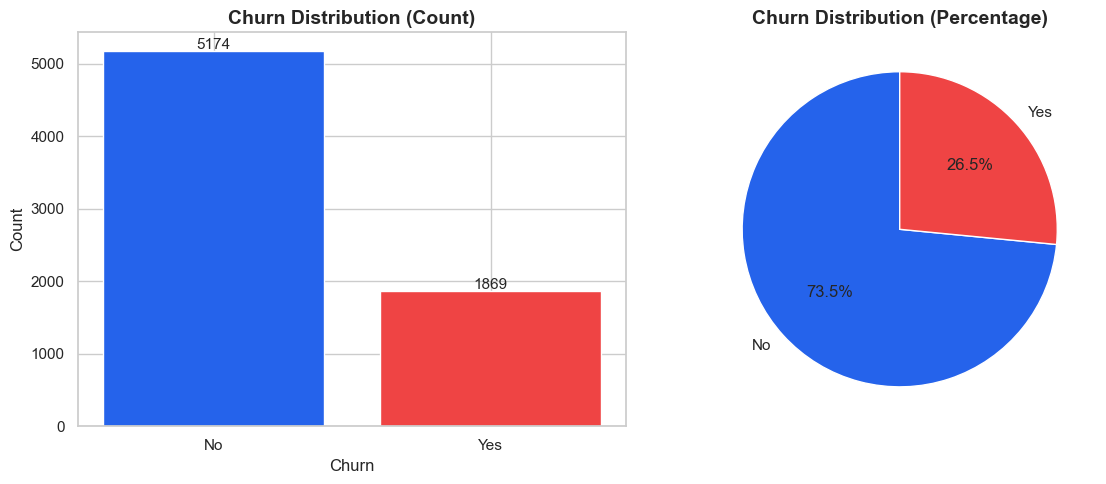

Churn Rate: 0.3%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

churn_counts = df['Churn'].value_counts()
axes[0].bar(churn_counts.index, churn_counts.values, color=['#2563EB', '#EF4444'])
axes[0].set_title('Churn Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Churn')
axes[0].set_ylabel('Count')
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 30, str(v), ha='center', fontsize=11)

axes[1].pie(churn_counts.values, labels=churn_counts.index, autopct='%1.1f%%', 
            colors=['#2563EB', '#EF4444'], startangle=90)
axes[1].set_title('Churn Distribution (Percentage)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()
print(f'Churn Rate: {churn_counts["Yes"] / len(df):.1f}%')

# 3. Churn vs Numerical Features

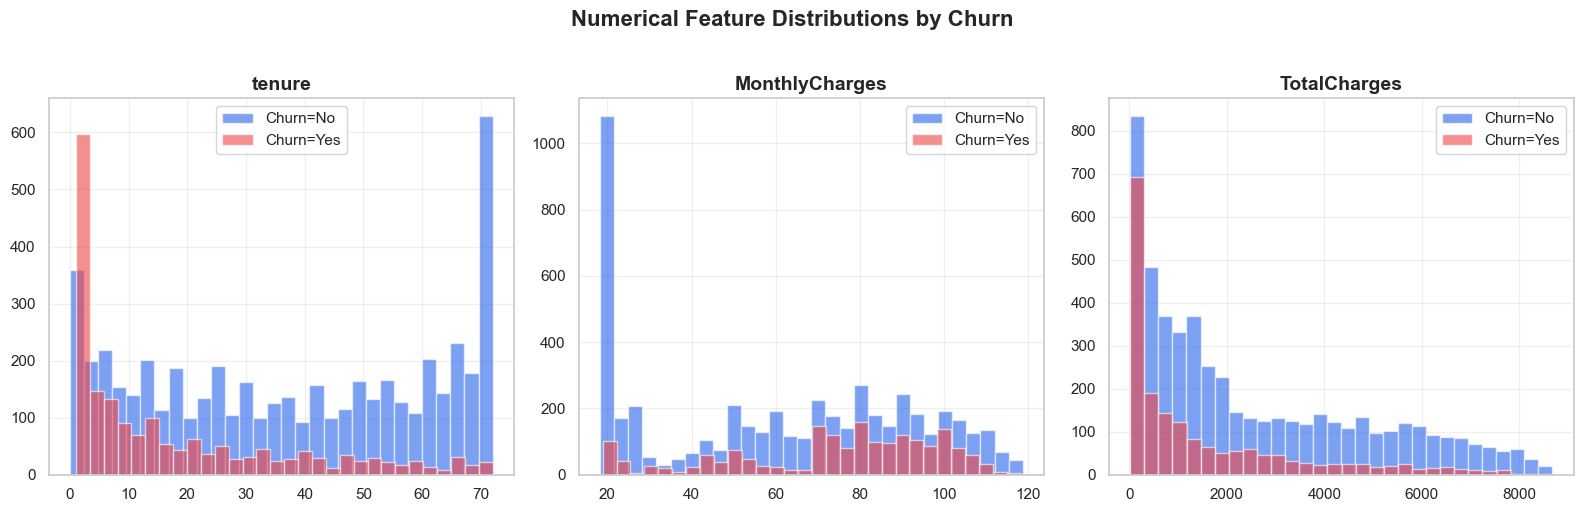

In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, col in enumerate(num_cols):
    for churn_val, color in [('No', '#2563EB'), ('Yes', '#EF4444')]:
        axes[i].hist(df[df['Churn'] == churn_val][col].dropna(), 
                    label=f'Churn={churn_val}', color=color, alpha=0.6, bins=30)
        axes[i].set_title(col, fontsize=14, fontweight='bold')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)
plt.suptitle('Numerical Feature Distributions by Churn', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 4. Churn vs Categorical Features

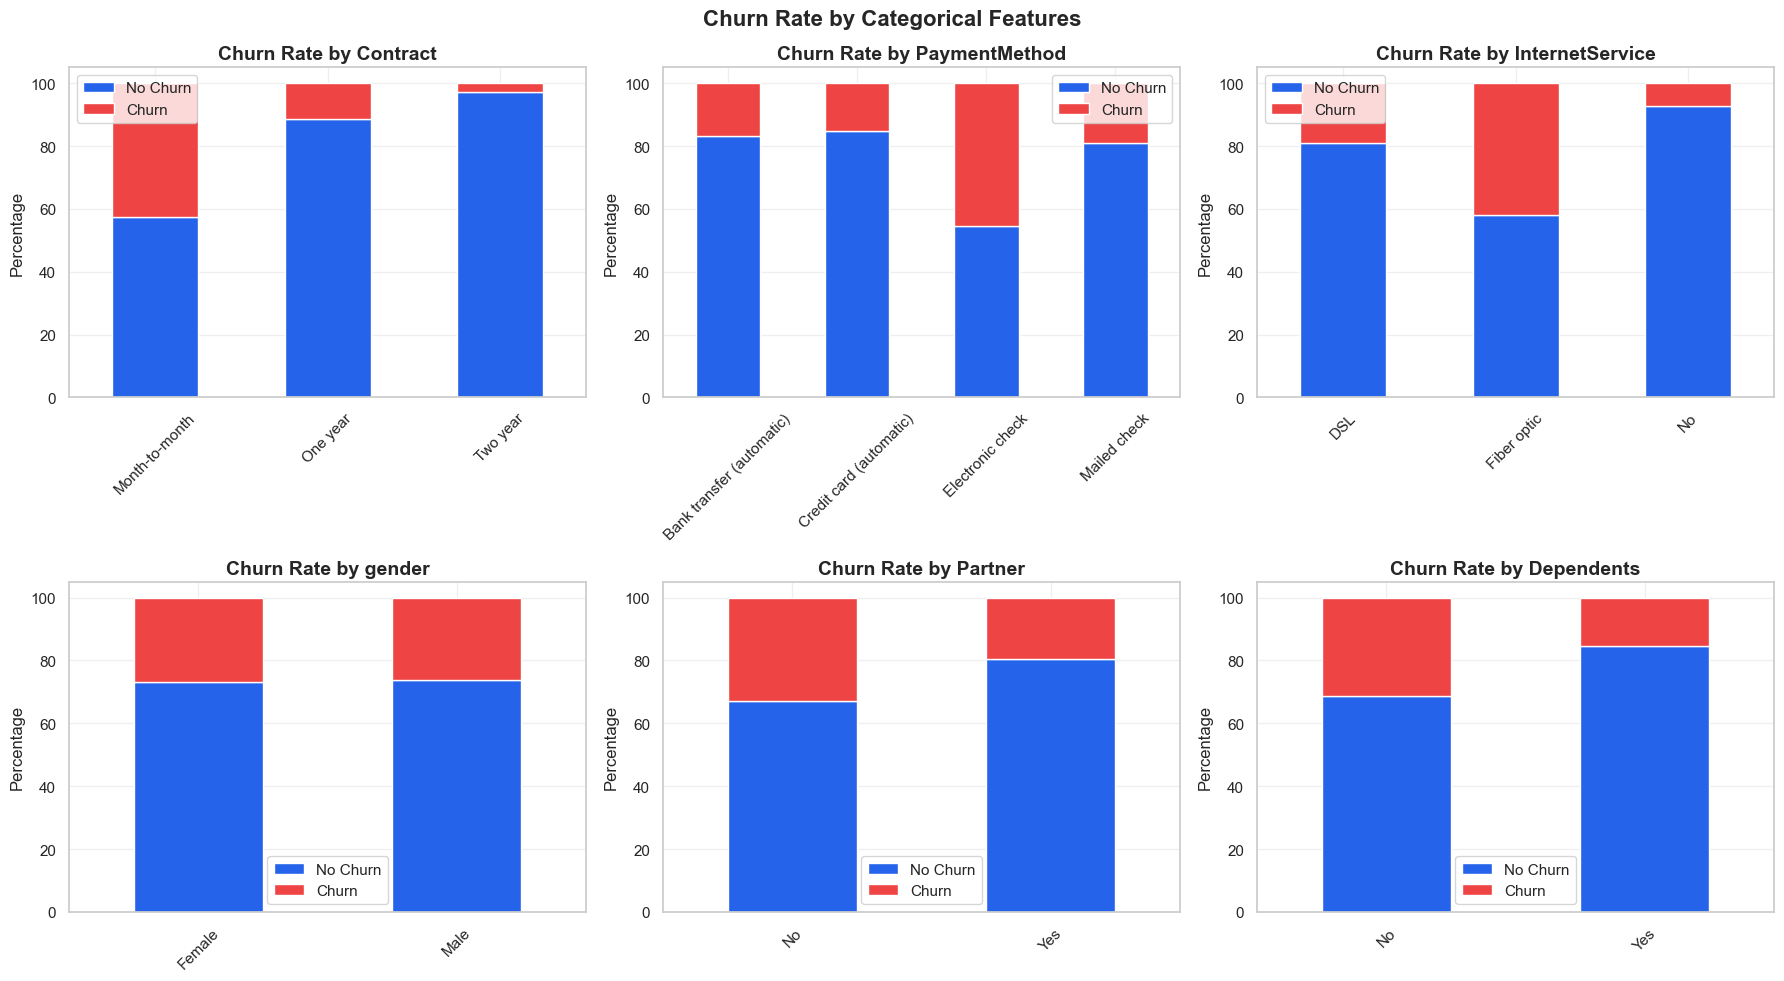

In [10]:
cat_cols =['Contract', 'PaymentMethod', 'InternetService', 'gender', 'Partner', 'Dependents']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df[col], df['Churn'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=axes[i], color=['#2563EB', '#EF4444'],
            edgecolor='white', width=0.5)
    axes[i].set_title(f'Churn Rate by {col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Percentage')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(['No Churn', 'Churn'])
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Churn Rate by Categorical Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


# 5. Correlation Heatmap

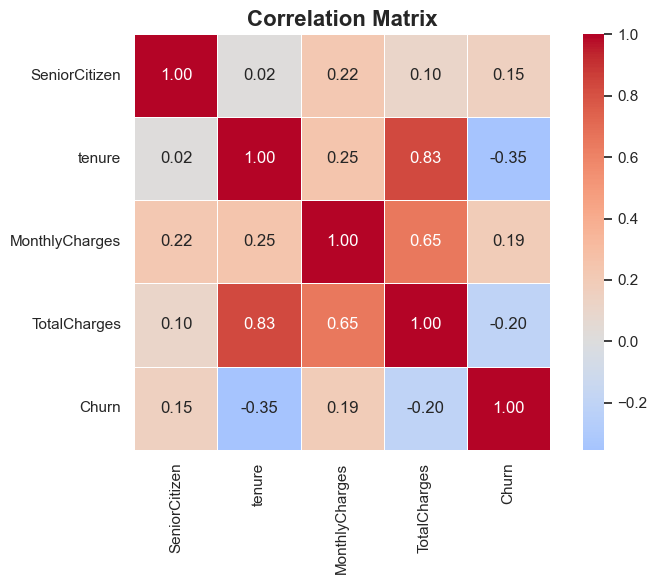

In [11]:
df_encoded = df.copy()
df_encoded['Churn'] = (df_encoded['Churn'] == 'Yes').astype(int)
df_encoded['TotalCharges'] = pd.to_numeric(df_encoded['TotalCharges'], errors='coerce')

corr_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr = df_encoded[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, 
            center=0, square=True)
plt.title('Correlation Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 6. Key Insight
- **Class imbalance**: ~26% churn rate -> need to handle in modeling
- **Tenure**: Customers with short tenure churn more
- **Contact type**: Month-to-month contracts have highest churn
- **MonthlyCharges**: Churning customers pay higher monthly fees
- **InternetService**: Fiber optic customers churn most
- **PaymentMethod**: Electronic check users churn at higher rates